In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("../data/telco_churn.xlsx")
df.to_csv("../data/telco_churn.csv", index=False)

In [7]:
df.shape

(7043, 33)

In [10]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges         object
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

In [11]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [13]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [14]:
df.columns = df.columns.str.strip().str.replace(" ", "_")
print(df.shape)
df.head()

(7043, 33)


,CustomerID,Count,Country,State,City,Zip_Code,Lat_Long,Latitude,Longitude,Gender,...,Contract,Paperless_Billing,Payment_Method,Monthly_Charges,Total_Charges,Churn_Label,Churn_Value,Churn_Score,CLTV,Churn_Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [15]:
# Tricky columns 
print(df["Churn_Value"].value_counts())
print(df["Churn_Value"].value_counts(normalize=True).round(3))

Churn_Value
0    5174
1    1869
Name: count, dtype: int64
Churn_Value
0    0.735
1    0.265
Name: proportion, dtype: float64


In [16]:
# Total_Charges can load as text with blank values
df["Total_Charges"] = pd.to_numeric(df["Total_Charges"], errors="coerce")
print(df["Total_Charges"].isnull().sum())
df[df["Total_Charges"].isnull()][["Tenure_Months", "Monthly_Charges", "Total_Charges"]]

11


,Tenure_Months,Monthly_Charges,Total_Charges
2234,0,52.55,NaN
2438,0,20.25,NaN
2568,0,80.85,NaN
2667,0,25.75,NaN
2856,0,56.05,NaN
4331,0,19.85,NaN
4687,0,25.35,NaN
5104,0,20.00,NaN
5719,0,19.70,NaN
6772,0,73.35,NaN


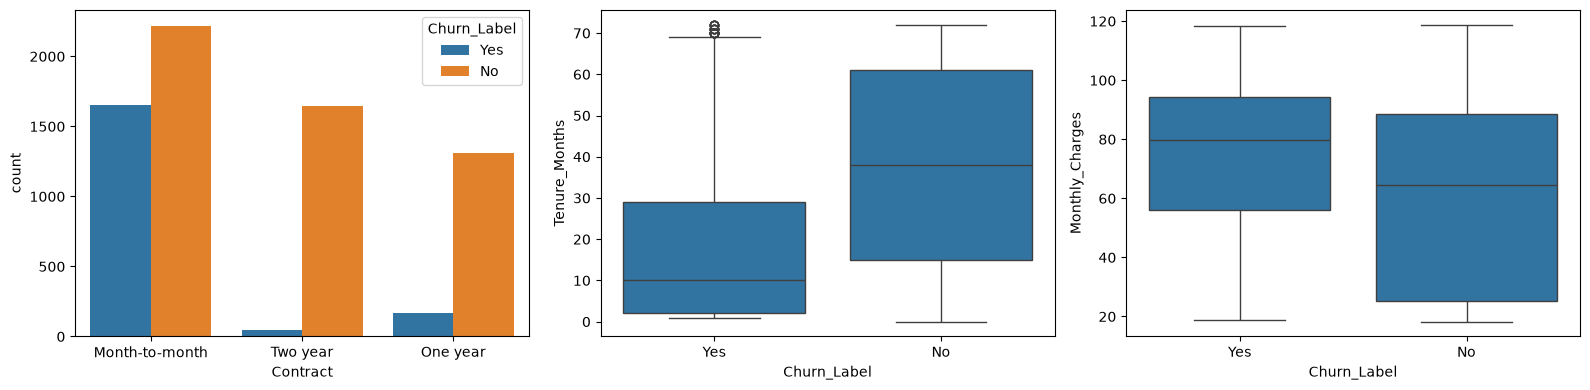

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Contract", hue="Churn_Label", ax=axes[0])
sns.boxplot(data=df, x="Churn_Label", y="Tenure_Months", ax=axes[1])
sns.boxplot(data=df, x="Churn_Label", y="Monthly_Charges", ax=axes[2])
plt.tight_layout()
plt.show()

In [18]:
for col in ["Contract", "Internet_Service", "Payment_Method"]:
    print(df.groupby(col)["Churn_Value"].mean().round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn_Value, dtype: float64 

Internet_Service
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn_Value, dtype: float64 

Payment_Method
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Electronic check             0.453
Mailed check                 0.191
Name: Churn_Value, dtype: float64 



Contract: Month-to-month customers churn at 42.7%, versus 2.8% for two-year contracts. That’s a 15x gap.
Internet service: Fiber optic customers churn at 41.9%, more than double DSL (19%). This is worth flagging as a possible pricing or quality issue.
Payment method: Electronic check users churn at 45.3%, versus around 15 to 17% for automatic payments

In [19]:
drop_cols = [
    "CustomerID", "Count", "Country", "State", "City", "Zip_Code",
    "Lat_Long", "Latitude", "Longitude",
    "Churn_Label", "Churn_Score", "CLTV", "Churn_Reason",
]
df_model = df.drop(columns=drop_cols)
df_model.to_csv("../data/telco_clean.csv", index=False)

print(df_model.shape)
df_model.columns.tolist()

(7043, 20)


['Gender',
 'Senior_Citizen',
 'Partner',
 'Dependents',
 'Tenure_Months',
 'Phone_Service',
 'Multiple_Lines',
 'Internet_Service',
 'Online_Security',
 'Online_Backup',
 'Device_Protection',
 'Tech_Support',
 'Streaming_TV',
 'Streaming_Movies',
 'Contract',
 'Paperless_Billing',
 'Payment_Method',
 'Monthly_Charges',
 'Total_Charges',
 'Churn_Value']

## Step 3: Preprocessing.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

df = pd.read_csv("../data/telco_clean.csv")

# Make sure Total_Charges is numeric (blank strings become NaN)
df["Total_Charges"] = pd.to_numeric(df["Total_Charges"], errors="coerce")

X = df.drop(columns=["Churn_Value"])
y = df["Churn_Value"]

print(X.shape, y.shape)

(7043, 19) (7043,)


In [21]:
num_cols = ["Tenure_Months", "Monthly_Charges", "Total_Charges"]
cat_cols = [c for c in X.columns if c not in num_cols]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

Numeric: ['Tenure_Months', 'Monthly_Charges', 'Total_Charges']
Categorical: ['Gender', 'Senior_Citizen', 'Partner', 'Dependents', 'Phone_Service', 'Multiple_Lines', 'Internet_Service', 'Online_Security', 'Online_Backup', 'Device_Protection', 'Tech_Support', 'Streaming_TV', 'Streaming_Movies', 'Contract', 'Paperless_Billing', 'Payment_Method']


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(5634, 19) (1409, 19)
0.265 0.265


In [23]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

In [24]:
X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

print(X_train_t.shape)
print(preprocessor.get_feature_names_out()[:10])

(5634, 46)
['num__Tenure_Months' 'num__Monthly_Charges' 'num__Total_Charges'
 'cat__Gender_Female' 'cat__Gender_Male' 'cat__Senior_Citizen_No'
 'cat__Senior_Citizen_Yes' 'cat__Partner_No' 'cat__Partner_Yes'
 'cat__Dependents_No']


## Step 4: Train and compare models

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)
import matplotlib.pyplot as plt

# Churners are the minority class, so we weight them more heavily
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(round(scale_pos_weight, 2))

2.77


In [26]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=8, class_weight="balanced",
        random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss",
        random_state=42),
}

pipelines = {
    name: Pipeline([("prep", preprocessor), ("model", model)])
    for name, model in models.items()
}

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: ROC-AUC = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: ROC-AUC = 0.859 (+/- 0.012)
Random Forest: ROC-AUC = 0.862 (+/- 0.009)
XGBoost: ROC-AUC = 0.858 (+/- 0.010)


In [28]:
results = []
fitted = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,ROC-AUC,Precision,Recall,F1
Model,,,,
Logistic Regression,0.849,0.510,0.781,0.617
Random Forest,0.852,0.528,0.778,0.629
XGBoost,0.851,0.521,0.786,0.627


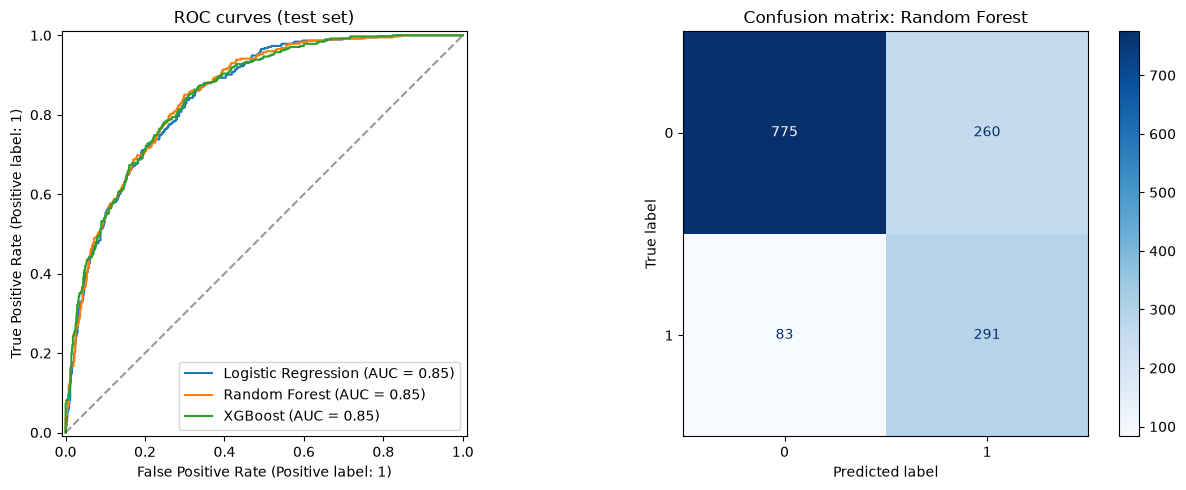

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curves (test set)")

best_name = results_df["ROC-AUC"].idxmax()
ConfusionMatrixDisplay.from_estimator(
    fitted[best_name], X_test, y_test, ax=axes[1], cmap="Blues")
axes[1].set_title(f"Confusion matrix: {best_name}")

plt.tight_layout()
plt.show()

## Step 5: SHAP explainability

In [32]:
import shap

final_pipe = fitted["XGBoost"]
prep = final_pipe.named_steps["prep"]
xgb_model = final_pipe.named_steps["model"]

# Transform the test set and give the columns readable names
X_test_t = prep.transform(X_test)
if hasattr(X_test_t, "toarray"):   # convert sparse -> dense if needed
    X_test_t = X_test_t.toarray()

feature_names = [n.replace("num__", "").replace("cat__", "")
                 for n in prep.get_feature_names_out()]
X_test_df = pd.DataFrame(X_test_t, columns=feature_names)

In [34]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_df)
print(shap_values.values.shape) 

(1409, 46)


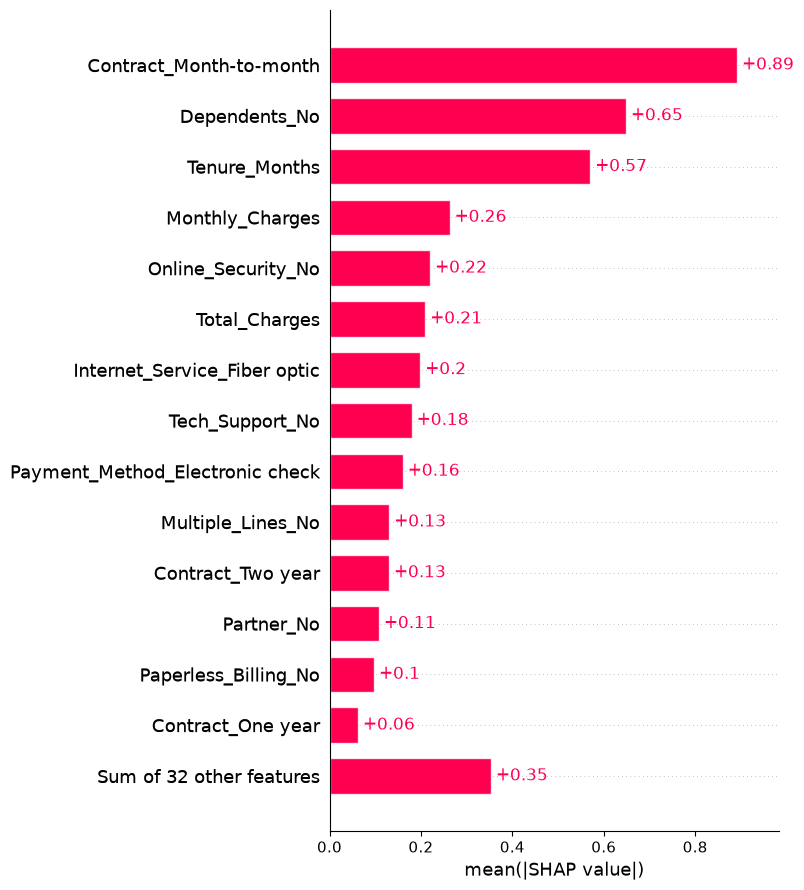

In [35]:
import os
os.makedirs("../images", exist_ok=True)

shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../images/shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

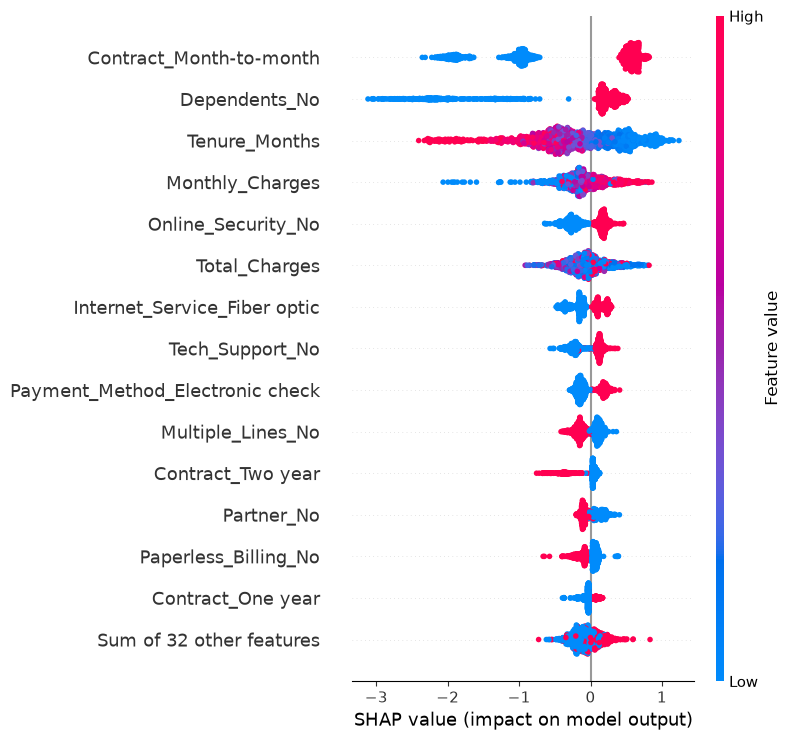

In [36]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../images/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

Churn probability: 0.978


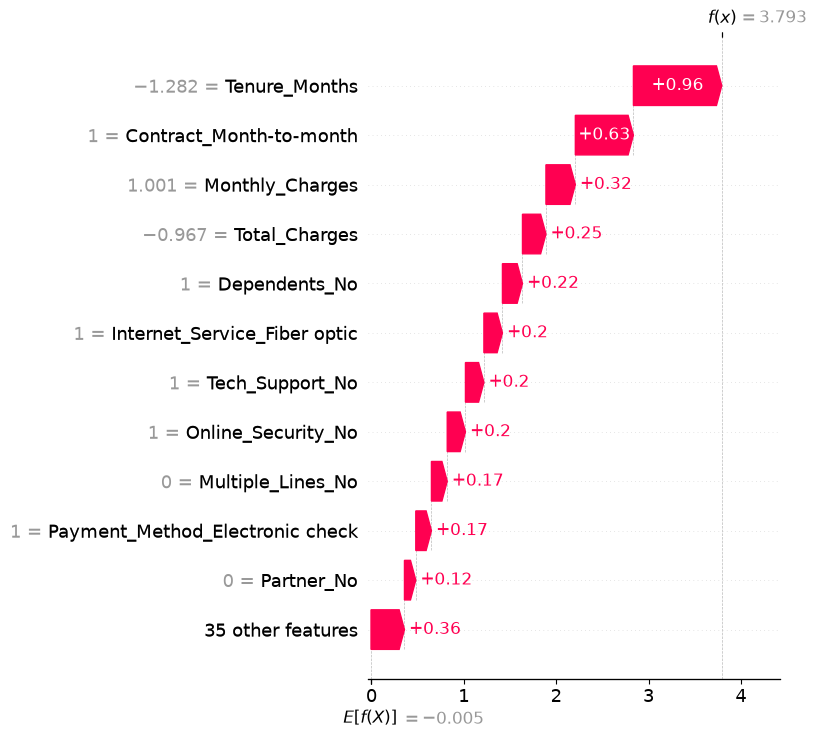

In [37]:
proba = final_pipe.predict_proba(X_test)[:, 1]
idx = int(np.argmax(proba))          # highest-risk customer in the test set
print("Churn probability:", round(proba[idx], 3))

shap.plots.waterfall(shap_values[idx], max_display=12, show=False)
plt.tight_layout()
plt.savefig("../images/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()